# Walk-through

This notebook shows each step of the two parts on real examples, then loads the saved results. Run it from the repository root after the data have been downloaded (see the README).

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

## Part 1. Operative notes

### 1.1 Selecting operative notes

In [2]:
from periop.notes.select import load_operative_notes
notes = load_operative_notes(ROOT / 'data' / 'mtsamples.csv')
print(len(notes), 'operative notes')
notes['specialty'].value_counts().to_frame('notes')

881 operative notes


,notes
specialty,
Surgery,781
Urology,91
Cardiovascular / Pulmonary,4
Obstetrics / Gynecology,3
Orthopedic,1
ENT - Otolaryngology,1


### 1.2 Snippet retrieval

A regular expression finds where the note talks about the variable. Only a short window around each hit is kept. The note below has about 3,500 characters; the snippet for blood loss has about 300.

In [3]:
from periop.notes.snippets import retrieve, RULES
note = notes.set_index('note_id').loc[614]
print(note['name'].strip(), '|', len(note['text']), 'characters\n')
for task in ('ebl', 'anes'):
    for s in retrieve(note['text'], task):
        print(f'[{task}] characters {s.start} to {s.end}:')
        print('   ', s.text.replace('\n', ' / '), '\n')

Laparotomy & Salpingectomy | 3506 characters

[ebl] characters 220 to 540:
    oratory laparotomy and right salpingectomy. / ANESTHESIA:  ,General endotracheal. / ESTIMATED BLOOD LOSS: , 200 mL. / COMPLICATIONS:  ,None. / FINDINGS: , Right ectopic pregnancy with brisk active bleeding approximately 1L of blood found in the abdomen cavity.  Normal-appearing ovaries bilaterally, normal-appearing left fallop 

[anes] characters 184 to 494:
    chycardia. / PROCEDURE PERFORMED: Exploratory laparotomy and right salpingectomy. / ANESTHESIA:  ,General endotracheal. / ESTIMATED BLOOD LOSS: , 200 mL. / COMPLICATIONS:  ,None. / FINDINGS: , Right ectopic pregnancy with brisk active bleeding approximately 1L of blood found in the abdomen cavity.  Normal-appearing ova 

[anes] characters 1599 to 1909:
    re. / PROCEDURE NOTE:  ,The patient was taken to the operating room where general anesthesia was administered without difficulty.  The patient was prepped and draped in the usual sterile fashion.  

### 1.3 Rule baseline on the same note

In [4]:
{task: RULES[task](note['text']) for task in ('ebl', 'anes')}

{'ebl': '200', 'anes': 'general'}

### 1.4 Reference labels and saved predictions

The language model takes a few minutes on a CPU, so the predictions of the reported run are loaded from `results/notes`.

In [5]:
labels = pd.read_csv(ROOT / 'annotations' / 'reference_labels.csv', dtype=str).fillna('')
pred = pd.read_csv(ROOT / 'results' / 'notes' / 'predictions.csv', dtype=str).fillna('')
labels.head(8)

,note_id,ebl,anes,comment
0,45,minimal,general,
1,88,5,not stated,'anesthetized' but type never named
2,102,not stated,regional,spinal with local infiltration and sedation
3,109,20,combined,general with caudal block
4,113,not stated,general,
5,123,not stated,general,
6,124,not stated,not stated,
7,134,not stated,general,


In [6]:
summary = json.loads((ROOT / 'results' / 'notes' / 'summary.json').read_text())
rows = []
for task, s in summary.items():
    for m in ('rules', 'llm_snippet', 'llm_full'):
        rows.append({'variable': task, 'method': m, 'accuracy': round(s[m]['accuracy'], 3), 'ci_low': round(s[m]['ci95'][0], 3),
                     'ci_high': round(s[m]['ci95'][1], 3), 'seconds_per_note': round(s[m]['seconds_per_note'], 4)})
pd.DataFrame(rows)

,variable,method,accuracy,ci_low,ci_high,seconds_per_note
0,anes,rules,0.767,0.650,0.867,0.0001
1,anes,llm_snippet,0.767,0.650,0.867,1.2797
2,anes,llm_full,0.733,0.617,0.850,4.2580
3,ebl,rules,0.983,0.950,1.000,0.0004
4,ebl,llm_snippet,0.783,0.667,0.883,0.4594
5,ebl,llm_full,0.417,0.300,0.550,3.8180


### 1.5 Where the language model goes wrong

The raw answers show the main failure: with no blood loss in the text, the model repeats the example given in the instruction.

In [7]:
g = pred[(pred.task == 'ebl') & (pred.llm_full != pred.truth)]
print(len(g), 'errors of the LLM on full notes (blood loss)')
pd.crosstab(g['truth'].where(g['truth'].isin(['not stated', 'minimal']), 'a number'), g['raw_full'].str.lower(), rownames=['reference'], colnames=['raw answer'])

35 errors of the LLM on full notes (blood loss)


raw answer,200 ml,5 ml,minimal,not stated
reference,,,,
a number,2,0,0,10
minimal,0,0,0,2
not stated,0,1,20,0


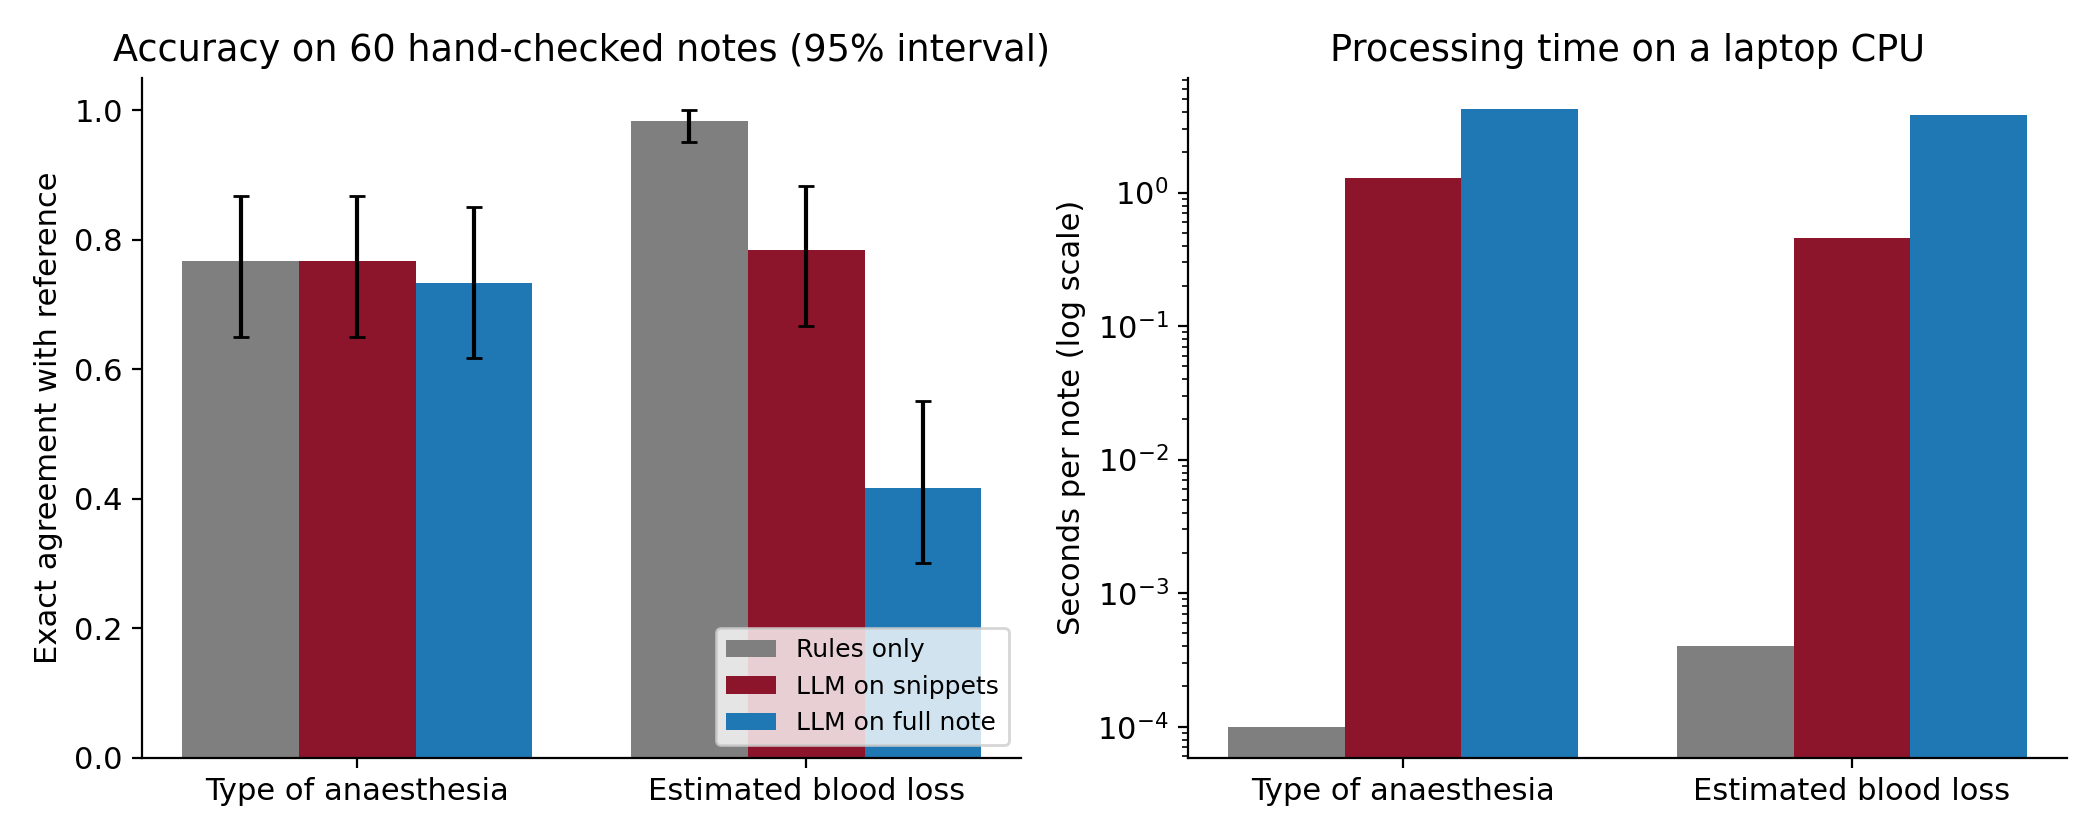

In [8]:
from IPython.display import Image
Image(str(ROOT / 'results' / 'figures' / 'notes_accuracy_time.png'), width=850)

## Part 2. Hypotension prediction

### 2.1 One arterial pressure recording

Raw waveform at 100 Hz, artefact removal, and MAP at 1 Hz.

art_0001.npy | 192 minutes | 11.9% of samples removed as artefact


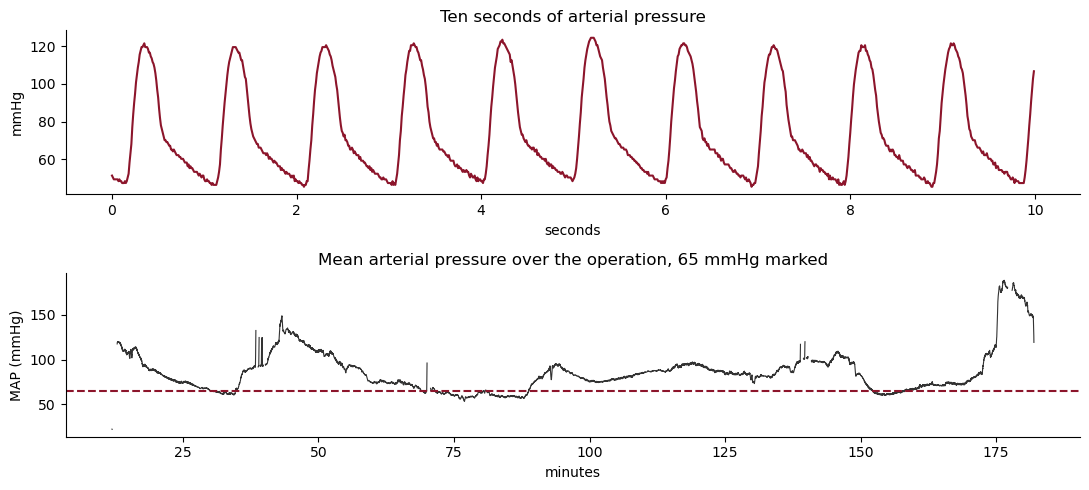

In [9]:
from periop.waveform.segments import clean, map_1hz, FS, HYPO
f = sorted((ROOT / 'data' / 'vitaldb').glob('art_*.npy'))[0]
art = np.load(f).astype(np.float32); a = clean(art); m = map_1hz(a)
print(f.name, '|', round(len(art) / FS / 60), 'minutes |', f'{np.isnan(a).mean():.1%} of samples removed as artefact')
fig, ax = plt.subplots(2, 1, figsize=(11, 5))
t0 = 60 * 60
ax[0].plot(np.arange(10 * FS) / FS, art[t0 * FS:(t0 + 10) * FS], color='#8c152b'); ax[0].set(xlabel='seconds', ylabel='mmHg', title='Ten seconds of arterial pressure')
ax[1].plot(np.arange(len(m)) / 60, m, color='#333333', lw=0.8); ax[1].axhline(HYPO, color='#8c152b', ls='--'); ax[1].set(xlabel='minutes', ylabel='MAP (mmHg)', title='Mean arterial pressure over the operation, 65 mmHg marked')
fig.tight_layout()

### 2.2 From a recording to labelled samples

Each sample is a moment t with its 30-s waveform, its 5-min MAP history, and the outcome 5 minutes later.

In [10]:
from periop.waveform.segments import samples_from_case
meta, waves, hist = samples_from_case(int(f.stem.split('_')[1]), art)
print(len(meta), 'samples;', int(meta.y.sum()), 'followed by hypotension;', int(meta.hypo_now.sum()), 'already hypotensive at t (excluded from the primary analysis)')
meta.head()

250 samples; 35 followed by hypotension; 45 already hypotensive at t (excluded from the primary analysis)


,caseid,t,map_now,y,hypo_now,future_min,future_max
0,1,1120,90.180000,0,0,73.401497,76.439003
1,1,1150,88.070251,0,0,73.247498,75.700500
2,1,1180,87.879501,0,0,73.247498,75.783501
3,1,1210,86.140503,0,0,73.277000,75.783501
4,1,1240,84.983002,0,0,71.672501,75.389999


### 2.3 Features of one sample

In [11]:
from periop.waveform.features import beat_features, trend_features
i = int(np.flatnonzero((meta.y == 1) & (meta.hypo_now == 0))[0]) if ((meta.y == 1) & (meta.hypo_now == 0)).any() else 0
feat = {**beat_features(waves[i]), **trend_features(hist[i])}
pd.Series(feat).round(2).to_frame('value').T

,wave_sd,dpdt_max,sbp,dbp,pp,hr,sbp_sd,pp_sd,rr_sd,map_now,map_mean_1m,map_mean_3m,map_mean_5m,map_min_5m,map_sd_5m,map_slope_1m,map_slope_5m,map_drop_from_max,time_below_75
value,21.49,1925.0,111.28,49.81,61.41,77.82,6.13,7.13,0.1,74.67,74.77,75.55,77.85,73.25,3.25,0.89,-2.12,10.77,0.25


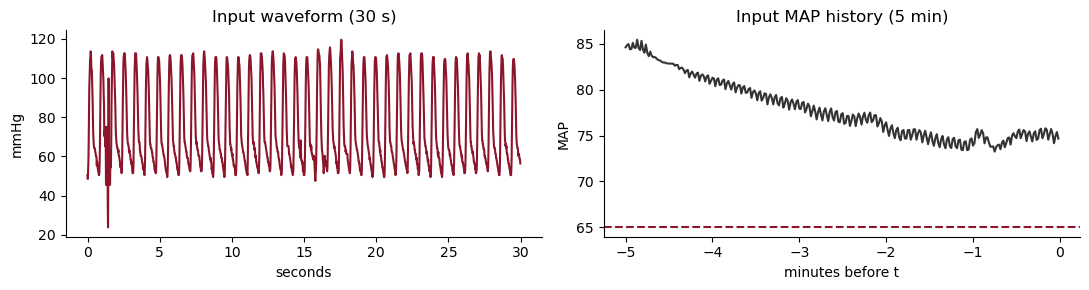

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(np.arange(1500) / 50, waves[i].astype(float), color='#8c152b'); ax[0].set(xlabel='seconds', ylabel='mmHg', title='Input waveform (30 s)')
ax[1].plot(np.arange(-300, 0) / 60, hist[i], color='#333333'); ax[1].axhline(65, color='#8c152b', ls='--'); ax[1].set(xlabel='minutes before t', ylabel='MAP', title='Input MAP history (5 min)')
fig.tight_layout()

### 2.4 Results of the reported run

In [13]:
res = json.loads((ROOT / 'results' / 'waveform' / 'metrics.json').read_text())
pd.DataFrame(res['cohort']).T

,patients,samples,events,event_rate
train,116.0,37653.0,1096.0,0.029108
val,38.0,13444.0,328.0,0.024398
test,40.0,12239.0,568.0,0.046409


In [14]:
rows = []
for name, v in res['metrics'].items():
    rows.append({'model': name, 'AUROC': round(v['auroc']['value'], 3), 'low': round(v['auroc']['ci95'][0], 3), 'high': round(v['auroc']['ci95'][1], 3),
                 'AUPRC': round(v['auprc']['value'], 3), 'sensitivity': round(v['sensitivity']['value'], 3), 'specificity': round(v['specificity']['value'], 3), 'PPV': round(v['ppv']['value'], 3)})
pd.DataFrame(rows)

,model,AUROC,low,high,AUPRC,sensitivity,specificity,PPV
0,map_only,0.752,0.646,0.867,0.151,0.595,0.806,0.130
1,record_only,0.740,0.649,0.812,0.095,0.880,0.473,0.075
2,wave_features,0.851,0.795,0.901,0.178,0.843,0.728,0.131
3,fusion,0.854,0.799,0.900,0.164,0.623,0.854,0.172
4,wave_cnn,0.837,0.774,0.896,0.196,0.792,0.727,0.124


In [15]:
pd.DataFrame({k: {'difference': round(v['value'], 3), 'low': round(v['ci95'][0], 3), 'high': round(v['ci95'][1], 3)} for k, v in res['auroc_differences'].items()}).T

,difference,low,high
wave_features_minus_map_only,0.100,0.012,0.194
fusion_minus_wave_features,0.002,-0.023,0.021
fusion_minus_map_only,0.102,0.005,0.204
wave_cnn_minus_map_only,0.086,-0.008,0.190
wave_cnn_minus_wave_features,-0.014,-0.042,0.007


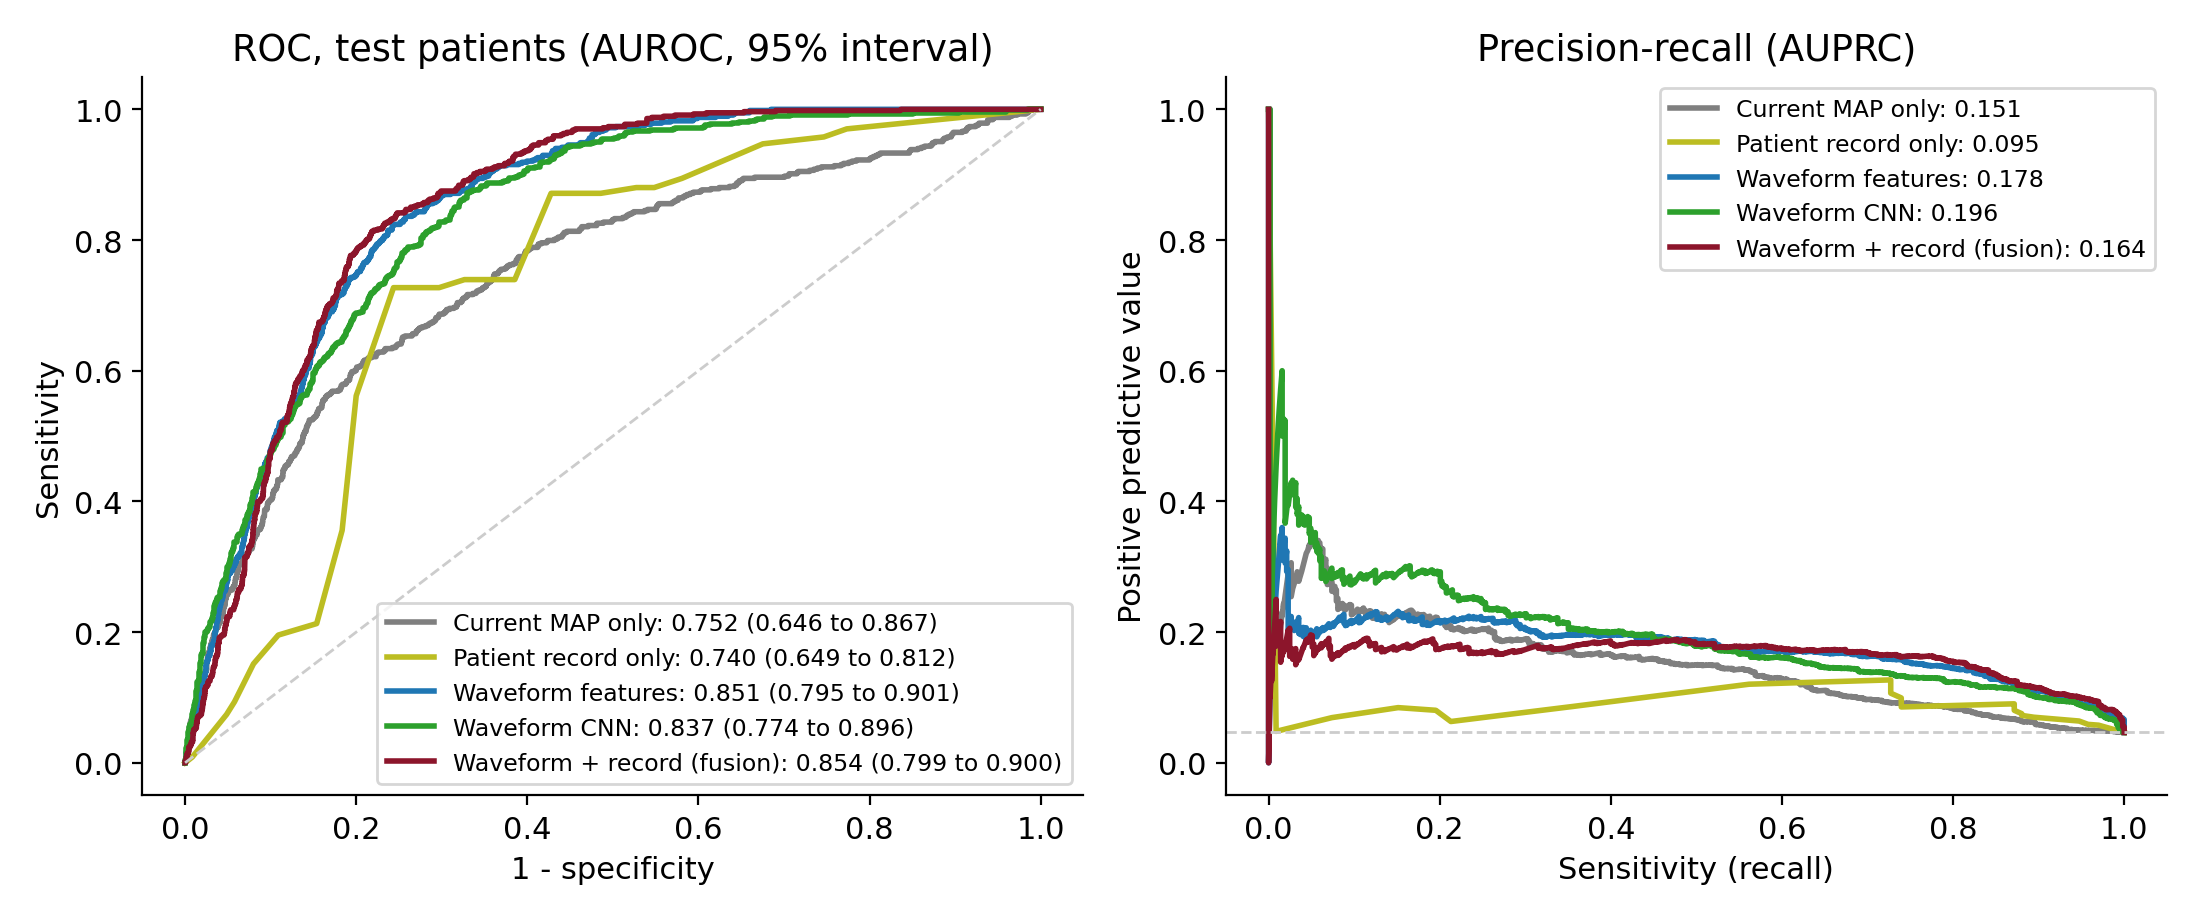

In [16]:
Image(str(ROOT / 'results' / 'figures' / 'waveform_roc_pr.png'), width=950)

### 2.5 The grey-zone selection

Same models, same test patients. Only the choice of which test samples to score changes.

In [17]:
pd.DataFrame({'all samples': {k: round(v['auroc']['value'], 3) for k, v in res['metrics'].items()}, 'grey zone removed': {k: round(v, 3) for k, v in res['grey_zone_test_auroc'].items()}})

,all samples,grey zone removed
map_only,0.752,0.829
record_only,0.740,0.802
wave_features,0.851,0.923
fusion,0.854,0.930
wave_cnn,0.837,0.916


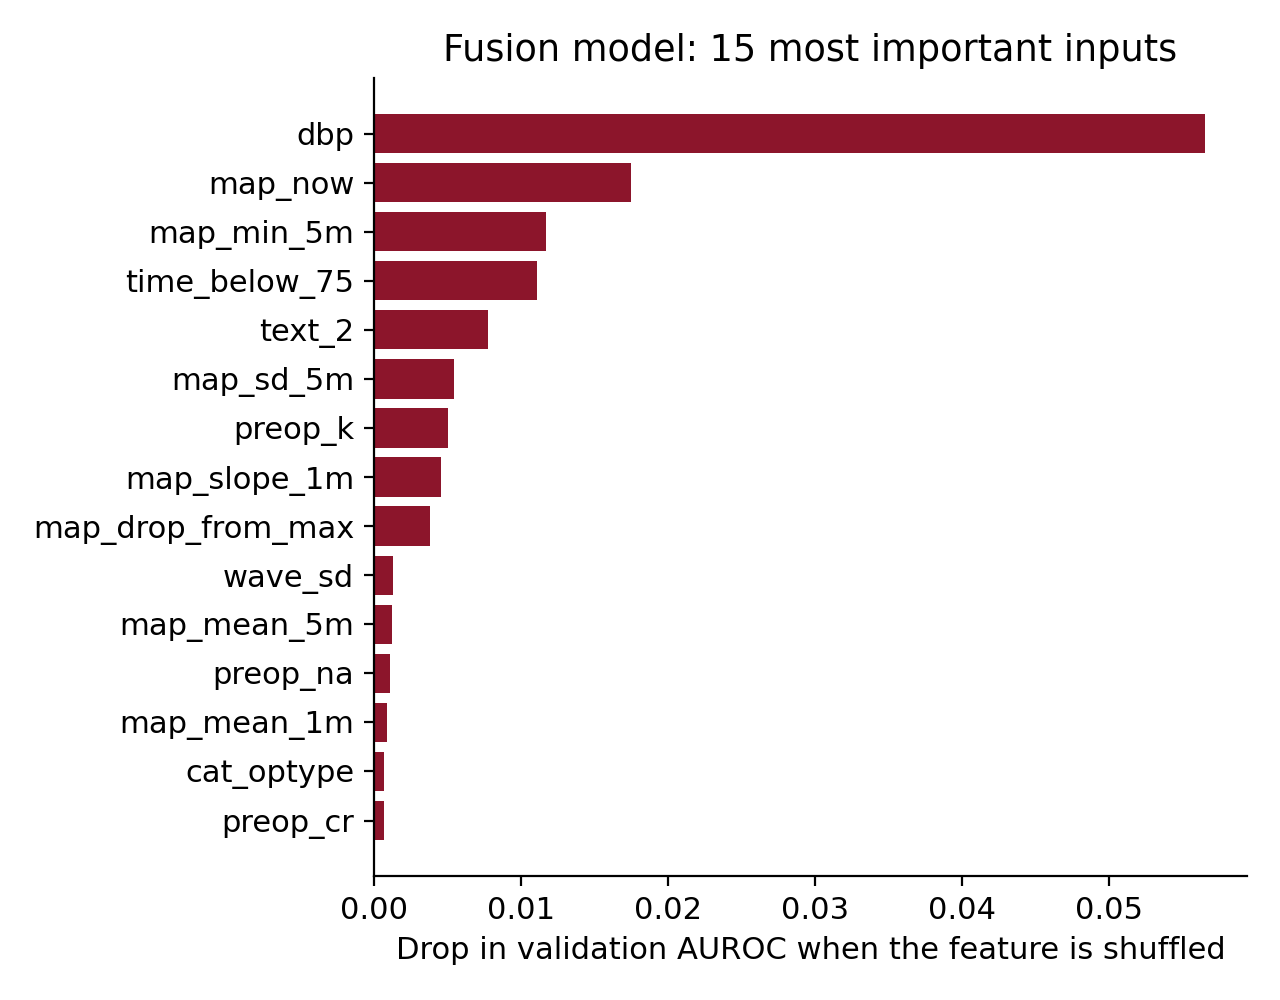

In [18]:
Image(str(ROOT / 'results' / 'figures' / 'fusion_importance.png'), width=560)